# 04 Landscape indices: toxicity and crop diversity (2025)

Input (in `data/raw/`, not in the repo):
- `output_2025_dot.csv`: land-use types within 500 m and 1000 m of each apiary, as hectares (`oppervlakte_ha`) and as a share of the buffer (`oppervlakte_procent`). Keyed by `id_location` only, no coordinates.
- `land_types.csv`: a foraging factor (0/1) and a pesticide factor for every land-use type.

Output (in `results/`, one row per apiary and radius, used by notebook 05):
- `04_toxicity_location_index_oppervlakte_procent.csv` (main) and `04_toxicity_location_index_oppervlakte_ha.csv`
- `04_crop_diversity_location_index.csv` (main) and `04_forage_diversity_location_index.csv`

Formulas, per apiary and radius:
- **Toxicity index** = sum(foraging factor x pesticide factor x oppervlakte_procent)
- **Crop diversity index** = number of land types with pesticide factor > 0 that cover more than 1% of the buffer
- **Forage diversity index** = number of land types with foraging factor = 1 that cover more than 1% of the buffer

The toxicity code is `calculate_toxicity_index.py` from the July 2026 analysis, with only the paths changed.
The diversity index was made in Excel in July; section 3 rebuilds it in code and gives the same numbers.

## 0. Paths and settings

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Run from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "raw"
RESULTS = ROOT / "results"
PLOTS = ROOT / "plots"
RESULTS.mkdir(exist_ok=True)
PLOTS.mkdir(exist_ok=True)

LAND_TYPES_PATH = DATA_DIR / "land_types.csv"
OUTPUT_2025_PATH = DATA_DIR / "output_2025_dot.csv"
RESULT_PROPORTION_PATH = RESULTS / "04_toxicity_location_index_oppervlakte_procent.csv"
RESULT_HECTARE_PATH = RESULTS / "04_toxicity_location_index_oppervlakte_ha.csv"
MISSING_TYPES_PATH = RESULTS / "04_missing_land_types.csv"
CROP_DIVERSITY_PATH = RESULTS / "04_crop_diversity_location_index.csv"
FORAGE_DIVERSITY_PATH = RESULTS / "04_forage_diversity_location_index.csv"

GROUP_COLUMNS = ["id_location", "jaar", "straal_m"]
FACTOR_COLUMNS = ["foraging factor", "pesticide factor"]
WEIGHT_OUTPUTS = {
    "oppervlakte_procent": RESULT_PROPORTION_PATH,
    "oppervlakte_ha": RESULT_HECTARE_PATH,
}

# A land type counts towards diversity only if it covers more than this share of the buffer
DIVERSITY_MIN_SHARE = 0.01

## 1. Functions (from `calculate_toxicity_index.py`, unchanged)

In [2]:
def require_columns(df: pd.DataFrame, required_columns: list[str], file_name: str) -> None:
    missing_columns = sorted(set(required_columns) - set(df.columns))
    if missing_columns:
        raise ValueError(
            f"{file_name} is missing required columns: {', '.join(missing_columns)}"
        )


def prepare_land_types(land_types: pd.DataFrame) -> pd.DataFrame:
    require_columns(land_types, ["type", *FACTOR_COLUMNS], LAND_TYPES_PATH.name)

    for column in FACTOR_COLUMNS:
        land_types[column] = pd.to_numeric(land_types[column], errors="coerce")

    invalid_factor_rows = land_types[land_types[FACTOR_COLUMNS].isna().any(axis=1)]
    if not invalid_factor_rows.empty:
        raise ValueError(
            "land_types.csv contains non-numeric factor values:\n"
            f"{invalid_factor_rows.to_string(index=False)}"
        )

    land_types = land_types.drop_duplicates(subset=["type", *FACTOR_COLUMNS])
    duplicated_types = land_types[
        land_types.duplicated("type", keep=False)
    ].sort_values("type")
    if not duplicated_types.empty:
        raise ValueError(
            "land_types.csv contains duplicate type rows with different factors:\n"
            f"{duplicated_types.to_string(index=False)}"
        )

    return land_types


def prepare_output(output: pd.DataFrame) -> pd.DataFrame:
    required_columns = [*GROUP_COLUMNS, "type", *WEIGHT_OUTPUTS.keys()]
    require_columns(output, required_columns, OUTPUT_2025_PATH.name)

    for column in WEIGHT_OUTPUTS:
        output[column] = pd.to_numeric(output[column], errors="coerce")

    invalid_weight_rows = output[output[list(WEIGHT_OUTPUTS)].isna().any(axis=1)]
    if not invalid_weight_rows.empty:
        raise ValueError(
            "output_2025_dot.csv contains non-numeric oppervlakte values:\n"
            f"{invalid_weight_rows.to_string(index=False)}"
        )

    return output


def calculate_toxicity_index(
    merged: pd.DataFrame,
    weight_column: str,
) -> pd.DataFrame:
    component_column = f"{weight_column}_toxicity_component"
    merged[component_column] = (
        merged["foraging factor"] * merged["pesticide factor"] * merged[weight_column]
    )

    return (
        merged.groupby(GROUP_COLUMNS, as_index=False)
        .agg(toxicity_index=(component_column, "sum"))
        [GROUP_COLUMNS + ["toxicity_index"]]
    )

## 2. Toxicity index
The body of `main()` from `calculate_toxicity_index.py`, split into steps.

In [3]:
land_types = pd.read_csv(LAND_TYPES_PATH)
output = pd.read_csv(OUTPUT_2025_PATH)

land_types = prepare_land_types(land_types)
output = prepare_output(output)

merged = output.merge(
    land_types[["type", *FACTOR_COLUMNS]],
    on="type",
    how="left",
    validate="many_to_one",
)

print(f"Land types: {len(land_types)}")
print(f"Apiaries: {output['id_location'].nunique()}, rows: {len(output)}")
print(output.groupby("straal_m")["id_location"].nunique().rename("apiaries per radius"))

Land types: 308
Apiaries: 423, rows: 21756
straal_m
500     422
1000    423
Name: apiaries per radius, dtype: int64


In [4]:
missing_mask = merged["foraging factor"].isna() | merged["pesticide factor"].isna()
if missing_mask.any():
    missing_summary = (
        merged.loc[missing_mask]
        .groupby("type", as_index=False)
        .agg(
            rows=("type", "size"),
            dropped_oppervlakte_procent=("oppervlakte_procent", "sum"),
            dropped_oppervlakte_ha=("oppervlakte_ha", "sum"),
        )
        .sort_values("dropped_oppervlakte_ha", ascending=False)
    )
    missing_summary.to_csv(MISSING_TYPES_PATH, index=False)
    print(
        f"Dropping {missing_mask.sum()} rows with {len(missing_summary)} "
        f"unmatched types. Details saved to: {MISSING_TYPES_PATH}"
    )
    merged = merged.loc[~missing_mask].copy()
else:
    print("Every land type in output_2025_dot.csv has factors in land_types.csv")

Every land type in output_2025_dot.csv has factors in land_types.csv


In [5]:
for weight_column, result_path in WEIGHT_OUTPUTS.items():
    result = calculate_toxicity_index(merged.copy(), weight_column)
    result.to_csv(result_path, index=False)
    print(f"Saved {len(result)} rows to: {result_path.relative_to(ROOT)}")

toxicity = pd.read_csv(RESULT_PROPORTION_PATH)
toxicity.groupby("straal_m")["toxicity_index"].describe().round(3)

Saved 845 rows to: results/04_toxicity_location_index_oppervlakte_procent.csv
Saved 845 rows to: results/04_toxicity_location_index_oppervlakte_ha.csv


,count,mean,std,min,25%,50%,75%,max
straal_m,,,,,,,,
500,422.0,0.939,1.943,0.0,0.000,0.100,0.915,13.300
1000,423.0,1.104,1.973,0.0,0.014,0.229,1.296,11.619


## 3. Diversity indices
Same merged table. A land type is counted once per apiary and radius when it covers more than 1% of the buffer.
Apiaries where no type passes the filter get 0.

In [6]:
def calculate_diversity_index(merged: pd.DataFrame, type_mask: pd.Series) -> pd.DataFrame:
    counted = merged.loc[type_mask & (merged["oppervlakte_procent"] > DIVERSITY_MIN_SHARE)]
    counts = counted.groupby(GROUP_COLUMNS)["type"].nunique().rename("diversity_index")
    all_groups = merged[GROUP_COLUMNS].drop_duplicates()
    result = all_groups.merge(counts.reset_index(), on=GROUP_COLUMNS, how="left")
    result["diversity_index"] = result["diversity_index"].fillna(0).astype(int)
    return result.sort_values(GROUP_COLUMNS).reset_index(drop=True)


crop_diversity = calculate_diversity_index(merged, merged["pesticide factor"] > 0)
forage_diversity = calculate_diversity_index(merged, merged["foraging factor"] == 1)

crop_diversity.to_csv(CROP_DIVERSITY_PATH, index=False)
forage_diversity.to_csv(FORAGE_DIVERSITY_PATH, index=False)
print(f"Saved {len(crop_diversity)} rows to: {CROP_DIVERSITY_PATH.relative_to(ROOT)}")
print(f"Saved {len(forage_diversity)} rows to: {FORAGE_DIVERSITY_PATH.relative_to(ROOT)}")

pd.concat({"crop": crop_diversity.groupby("straal_m")["diversity_index"].describe(),
           "forage": forage_diversity.groupby("straal_m")["diversity_index"].describe()}).round(2)

Saved 845 rows to: results/04_crop_diversity_location_index.csv
Saved 845 rows to: results/04_forage_diversity_location_index.csv


count  mean   std  min  25%  50%  75%   max
       straal_m                                             
crop   500       422.0  2.06  2.57  0.0  0.0  1.0  3.0  14.0
       1000      423.0  2.84  3.12  0.0  0.0  2.0  5.0  15.0
forage 500       422.0  4.15  3.18  0.0  2.0  3.0  6.0  19.0
       1000      423.0  4.95  3.62  0.0  2.0  4.0  7.0  17.0

## 4. Distribution of the indices

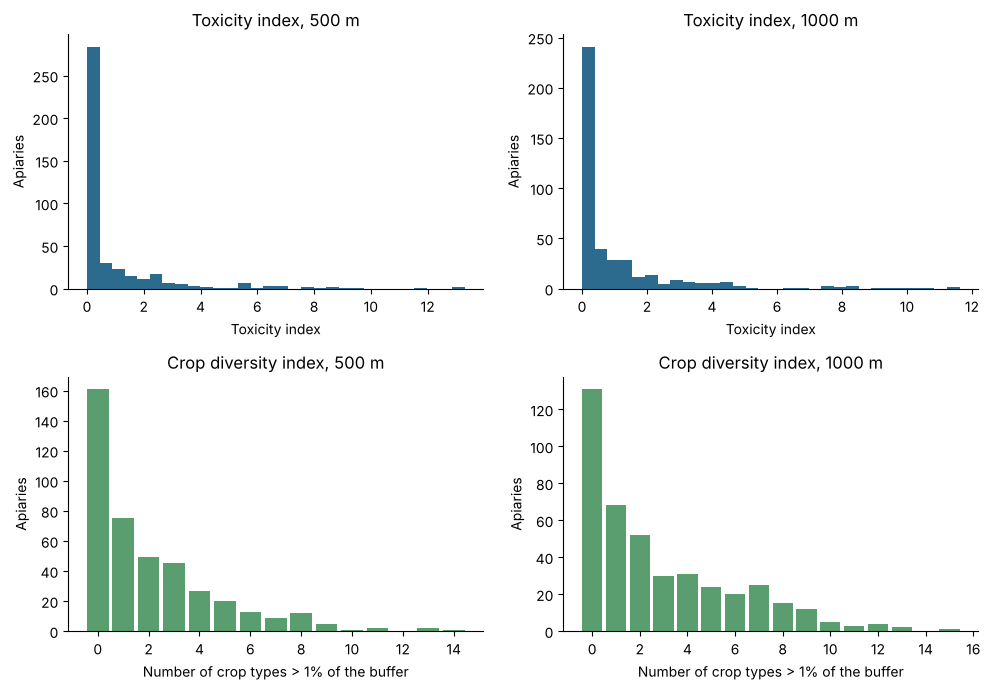

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for col, radius in enumerate([500, 1000]):
    tox = toxicity.loc[toxicity["straal_m"] == radius, "toxicity_index"]
    div = crop_diversity.loc[crop_diversity["straal_m"] == radius, "diversity_index"]
    axes[0, col].hist(tox, bins=30, color="#2c6b8e")
    axes[0, col].set_title(f"Toxicity index, {radius} m")
    axes[0, col].set_xlabel("Toxicity index")
    axes[1, col].hist(div, bins=range(0, int(div.max()) + 2), color="#5a9e6f", align="left", rwidth=0.85)
    axes[1, col].set_title(f"Crop diversity index, {radius} m")
    axes[1, col].set_xlabel("Number of crop types > 1% of the buffer")
for ax in axes.flat:
    ax.set_ylabel("Apiaries")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(PLOTS / "04_index_distributions.png", dpi=200, bbox_inches="tight")
plt.show()